# Chapter 3 · learn, drive, cooperate
**Instructor edition · Apple Silicon Mac · CPU · approximately 55–60 minutes**

Four tasks connect an agent's observations, actions, and rewards:
a dessert café, highway navigation, Prisoner's Dilemma, and Simple Spread.
We begin with NumPy arrays, then use PyTorch to approximate action values.


| Video segment | Topic |
|---|---|
| 00–04 | Four tasks and the agent–environment loop |
| 04–12 | NumPy arrays and PyTorch tensors |
| 12–28 | Café decisions and tabular Q-learning |
| 28–46 | Highway observations, a DQN, and evaluation |
| 46–52 | Prisoner's Dilemma and tit-for-tat |
| 52–58 | Simple Spread and shared team reward |
| 58–60 | Reflection and extensions |

The student edition follows the same order with five exercise blocks.
Synthetic café demand and prices are teaching assumptions.

**Presenter cue:** Introduce the observation → action → reward loop.
Each task has its own illustrated explanation at the start of its section.
Prisoner's Dilemma awards separate player payoffs; Simple Spread awards one identical
coverage score to every agent. Optional long experiments are outside the 60-minute core.

## 0 · Start the local kernel
Create the environment once using the repository README, then choose the **Python (RL Chapter 3)** kernel.
This notebook checks its environment; it does not install or upgrade packages.
Widgets run in JupyterLab. Ordinary code alternatives accompany the controls.

In [1]:
import os, sys, copy, json, time
from pathlib import Path
from importlib.metadata import version

# Find the project from either the repository root or notebooks/.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'rl_lab').is_dir() and (p / 'environment.yml').is_file()), None)
if ROOT is None:
    raise RuntimeError('Open JupyterLab from the cloned repository; see README.md.')
sys.path.insert(0, str(ROOT))
import rl_lab  # Sets headless rendering before importing pygame or matplotlib.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from IPython.display import display, Image, Markdown
from IPython import get_ipython
if get_ipython() is not None:
    get_ipython().run_line_magic("matplotlib", "inline")
from rl_lab.rules import LearningRules
from rl_lab.checks import (check_foundations, check_dqn,
                           check_tit_for_tat, check_team_reward)
from rl_lab.cafe import (DessertCafe, CafeQAgent, cafe_episode, cafe_evaluate,
                         train_cafe, plot_cafe, plot_cafe_policy)
from rl_lab.highway import (HIGHWAY_CONFIG, ACTION_NAMES, make_highway, random_argmax,
                            highway_comparison, plot_highway_comparison,
                            highway_rollout, highway_evaluate, PlaybackDQN,
                            load_cached_comparison)
from rl_lab.social import (read_payoffs, plot_payoffs, social_match,
                           train_social, plot_social)
from rl_lab.spread import (make_spread, reset_spread, spread_positions,
                            spread_rollout, plot_spread_comparison)
from rl_lab.practice import cafe_controls, dilemma_controls, spread_controls

if sys.version_info[:2] != (3, 11):
    raise RuntimeError(f'Select the Python 3.11 lab kernel. Current Python: {sys.executable}')
torch.set_num_threads(1)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False,
                     'axes.spines.right': False})
VERSIONS = {name: version(name) for name in
            ['numpy','torch','gymnasium','highway-env','pettingzoo','mpe2','matplotlib','pandas']}
print('Kernel:', sys.executable)
print('Versions:', VERSIONS)

Kernel: /Users/sarahxu/Desktop/Coding-session-for-Neuroscience-inspired-AI/.conda/bin/python
Versions: {'numpy': '1.26.4', 'torch': '2.5.1', 'gymnasium': '1.2.3', 'highway-env': '1.10.2', 'pettingzoo': '1.25.0', 'mpe2': '0.0.1', 'matplotlib': '3.9.4', 'pandas': '2.2.3'}


In [2]:
# 'smoke': fast code check; 'teaching': video/practice; 'experiment': longer multi-seed run.
RUN_MODE = os.environ.get('CH3_RUN_MODE', 'teaching')
RUN_HIGHWAY_TRAINING = os.environ.get('CH3_TRAIN_HIGHWAY', '0') == '1'
RUN_SOCIAL_TRAINING = False   # Optional Prisoner's Dilemma learners only.
SHOW_WIDGETS = True
DEVICE = 'cpu'
if RUN_MODE not in {'smoke','teaching','experiment'}:
    raise ValueError('Choose smoke, teaching, or experiment.')
BUDGETS = {
    'smoke': dict(cafe=200, highway=256, eval_n=2, seeds=[0], social=20),
    'teaching': dict(cafe=20000, highway=2000, eval_n=10, seeds=[0], social=300),
    'experiment': dict(cafe=60000, highway=20000, eval_n=30, seeds=[0,1,2], social=1500),
}
budget = BUDGETS[RUN_MODE]
OUTPUT_DIR = rl_lab.RESULTS / (RUN_MODE + '_' + time.strftime('%Y%m%d_%H%M%S'))
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print('Budget:', budget)
print('Highway comparison:', 'TRAIN NEW AGENTS' if RUN_HIGHWAY_TRAINING else 'LOAD RECORDED TEACHING RUN')
print('Results directory:', OUTPUT_DIR)

Budget: {'cafe': 20000, 'highway': 2000, 'eval_n': 10, 'seeds': [0], 'social': 300}
Highway comparison: LOAD RECORDED TEACHING RUN
Results directory: /Users/sarahxu/Desktop/Coding-session-for-Neuroscience-inspired-AI/results/teaching_20261031_171901


`smoke` checks code paths and is too small to judge learning. The default highway display
loads a recorded, matched-budget teaching run to keep the recording moving.
Set `RUN_HIGHWAY_TRAINING = True` to train with your own functions, and rerun from setup.
`experiment` increases the budget, but still needs the training flag to start new highway training.
No ranking should be inferred from a single training seed.

## 1 · The array-to-tensor bridge

**NumPy:** an array stores numbers; a mask selects allowed entries; indexing selects a row or action.
Here a row is a state and a column is an action. Predict the printed shapes before running.

In [3]:
q_demo = np.array([[1., 4., 2.], [3., -1., 5.]], dtype=np.float32)
valid_actions = np.array([True, False, True])
print('Q-table shape:', q_demo.shape)
print('Values in state 0:', q_demo[0])
print('Allowed action indices:', np.flatnonzero(valid_actions))
print('Allowed values in state 0:', q_demo[0, valid_actions])
print('Masking does not change the original table:', q_demo)
# Try: change the mask, then predict which action is feasible AND most valuable.

Q-table shape: (2, 3)
Values in state 0: [1. 4. 2.]
Allowed action indices: [0 2]
Allowed values in state 0: [1. 2.]
Masking does not change the original table: [[ 1.  4.  2.]
 [ 3. -1.  5.]]


**PyTorch:** a tensor also has a shape and dtype. With `requires_grad=True`, PyTorch tracks
operations so `backward()` can calculate gradients. An optimizer uses those gradients to
change parameters. A forward pass alone does not train a network.

In [4]:
torch.manual_seed(0)
x = torch.tensor([[1., 2.], [3., 4.]], dtype=torch.float32)  # batch of 2 examples
tiny_model = nn.Linear(2, 1)
optimizer_demo = torch.optim.SGD(tiny_model.parameters(), lr=.01)
prediction = tiny_model(x)
target_demo = torch.tensor([[1.], [2.]])
loss_demo = ((prediction - target_demo) ** 2).mean()
optimizer_demo.zero_grad()
loss_demo.backward()
print('Input:', tuple(x.shape), 'prediction:', tuple(prediction.shape))
print('Weight gradient:', tiny_model.weight.grad)
optimizer_demo.step()
print('One parameter update completed.')
# Predict: what would happen if optimizer_demo.step() were omitted?

Input: (2, 2) prediction: (2, 1)
Weight gradient: tensor([[-4.0703, -5.9795]])
One parameter update completed.


**Keep this reference nearby:**

| Operation | NumPy | PyTorch |
|---|---|---|
| Create floating values | `np.array(data, dtype=np.float32)` | `torch.tensor(data, dtype=torch.float32)` |
| Inspect dimensions | `x.shape` | `x.shape` |
| Maximum per row | `x.max(axis=1)` | `x.max(dim=1).values` |
| Integer action indices | `np.int64` | `torch.long` |
| Matrix multiplication | `a @ b` | `a @ b` |
| Stop gradient tracking | No automatic gradients | `with torch.no_grad():` or `x.detach()` |

Neither `axis=1` nor `dim=1` means “time” automatically: it means the second array dimension.
For a batch of action values, that dimension represents actions.

**Presenter cue:** Point out NumPy's `axis` versus a tensor's `dim`, integer action indices,
and the leading batch dimension. In RL we will construct targets from observed rewards
instead of receiving a labelled dataset. Omit the optimizer step and parameters do not change.

## 2 · Café Q-learning

![Black-and-white cafe: one blue cookie and one pink cake match the blue cookie and pink cake demand curves.](../assets/figures/task_cafe.png)

**Read the figure:** 1 links the blue cookie to its blue demand curve; 2 links the pink cake to its pink curve. These demand patterns are schematic.

Manage Dubai chewy cookies (두쫀쿠) and pistachio cake. Cake demand peaks earlier; cookie demand peaks later.
The café is a small, finite-horizon decision problem.

| Element | Meaning |
|---|---|
| State | Hour, cookie inventory, cake inventory, remaining ingredients |
| Action | Prepare `(0,0), (2,0), (0,2), (4,0), (2,2), (0,4)` portions |
| Timing | Sell current stock this hour; new preparation arrives next hour |
| Resources | 24 preparation units during the day; capacity 8 per dessert |
| Opening | 2 of each dessert, prepared before opening and charged at cost |
| Prices / costs | Cookie: 6 / 3 credits; cake: 7 / 4 credits |
| Reward | Cash profit minus 0.5 credits per unserved customer |
| Closing | 6 p.m.; discard stock for 1 credit per portion; no final-hour preparation |

Your action must respect the ingredient, capacity, and final-hour mask.
The simulator pre-generates customers so policies can be evaluated on the same customer days.

### Exercise 1 · exploration and a Q-learning update

Implement three functions. Exploration must also respect the action mask.
Break equal-value greedy ties randomly; otherwise the first action gets an accidental advantage.


\[
y=r+\gamma(1-\mathrm{terminated})\max_{a'\,\mathrm{valid}}Q(s',a'),
\qquad Q(s,a)\leftarrow Q(s,a)+\alpha[y-Q(s,a)].
\]

**Hint:** `np.flatnonzero(mask)` gives feasible action indices. The largest value may be negative.

In [5]:
def epsilon_greedy(values, epsilon, rng, mask=None):
    values = np.asarray(values, dtype=float)
    mask = np.ones(len(values), dtype=bool) if mask is None else np.asarray(mask, bool)
    valid = np.flatnonzero(mask)
    if not len(valid):
        raise ValueError('No feasible action.')
    if rng.random() < epsilon:
        return int(rng.choice(valid))
    best = valid[values[valid] == values[valid].max()]
    return int(rng.choice(best))

def td_target(reward, terminated, next_values, next_mask, gamma):
    if terminated:
        return float(reward)
    next_values = np.asarray(next_values)
    next_mask = np.asarray(next_mask, dtype=bool)
    return float(reward + gamma * next_values[next_mask].max())

def q_update(old_value, target, alpha):
    return float(old_value + alpha * (target - old_value))

In [6]:
check_foundations(epsilon_greedy, td_target, q_update)
rules = LearningRules(epsilon_greedy, td_target, q_update)

Exercise 1 passed: masking, exploration, ties, terminal targets, negative values and updates.


**Presenter cue:** Work through `old=1, target=3, alpha=.25 → 1.5` by hand first.
The terminal target is reward even if a stored next-state value is huge.
The café uses `gamma=1` because it optimizes the day's total reward and time is part of the state.

### Exercise 2 · run the café, then explain the policy

Before viewing demand, choose how many desserts to prepare.
The controls reveal each hour's outcome only after your decision.
Try the same seed twice and explain one change in your plan.

In [7]:
if SHOW_WIDGETS:
    cafe_ui = cafe_controls(seed=2026)

**Ordinary-code alternative:** edit the eight action indices below and rerun.
An infeasible choice becomes waiting in this manual demo, and is explicitly reported.
The simulator itself rejects infeasible actions.

In [8]:
MANUAL_ACTIONS = [2, 5, 4, 1, 1, 3, 0, 0]
manual_env = DessertCafe()
invalid_requests = []
def manual_policy(state, mask):
    requested = MANUAL_ACTIONS[int(state[0])]
    if requested not in range(len(mask)) or not mask[requested]:
        invalid_requests.append((10 + int(state[0]), requested))
        return 0
    return int(requested)
manual_return, manual_rows = cafe_episode(manual_env, manual_policy, seed=2026)
display(pd.DataFrame([{
    'hour': r['hour'], 'stock': tuple(r['inventory']), 'prepare_next': tuple(r['produced']),
    'demand': tuple(r['demand']), 'sales': tuple(r['sales']), 'cash_profit': r['cash_profit']
} for r in manual_rows]))
print('Return:', manual_return, '| Requests replaced by waiting:', invalid_requests)
manual_env.close()

,hour,stock,prepare_next,demand,sales,cash_profit
0,10,"(2, 2)","(0, 2)","(0, 1)","(0, 1)",-15.0
1,11,"(2, 3)","(0, 4)","(0, 2)","(0, 2)",-2.0
2,12,"(2, 5)","(2, 2)","(2, 4)","(2, 4)",26.0
3,13,"(2, 3)","(2, 0)","(1, 6)","(2, 3)",27.0
4,14,"(2, 0)","(2, 0)","(1, 2)","(1, 0)",0.0
5,15,"(3, 0)","(4, 0)","(2, 2)","(3, 0)",6.0
6,16,"(4, 0)","(0, 0)","(8, 1)","(4, 0)",24.0
7,17,"(0, 0)","(0, 0)","(6, 1)","(0, 0)",0.0


Return: 57.5 | Requests replaced by waiting: []


The provided agent stores `Q[hour, cookies, cakes, ingredients, action]` in a NumPy array.
The training loop below shows where your three functions enter. The full simulator and
bookkeeping are in `rl_lab/cafe.py`.

In [9]:
# One learning transition, with all three student functions visible.
demo_env = DessertCafe()
demo_agent = CafeQAgent(demo_env, rules, seed=0)
state, info = demo_env.reset(seed=0)
action = epsilon_greedy(demo_agent.q[tuple(state)], .2, demo_agent.rng, info['action_mask'])
next_state, reward, terminated, truncated, next_info = demo_env.step(action)
target = td_target(reward, terminated, demo_agent.q[tuple(next_state)], next_info['action_mask'], demo_agent.gamma)
index = (*state, action)
demo_agent.q[index] = q_update(demo_agent.q[index], target, demo_agent.alpha)
print('Updated index:', index, '| target:', target, '| Q:', demo_agent.q[index])
demo_env.close()

Updated index: (0, 2, 2, 24, 3) | target: -26.0 | Q: -3.9


Café: 20,000 days, 160,000 training transitions, 11.1s; 2,140 visited states.


,return,profit,waste,missed
Tabular Q-learning,47.38,52.14,0.79,9.52
Forecast-based rule,54.70,57.61,2.06,5.81


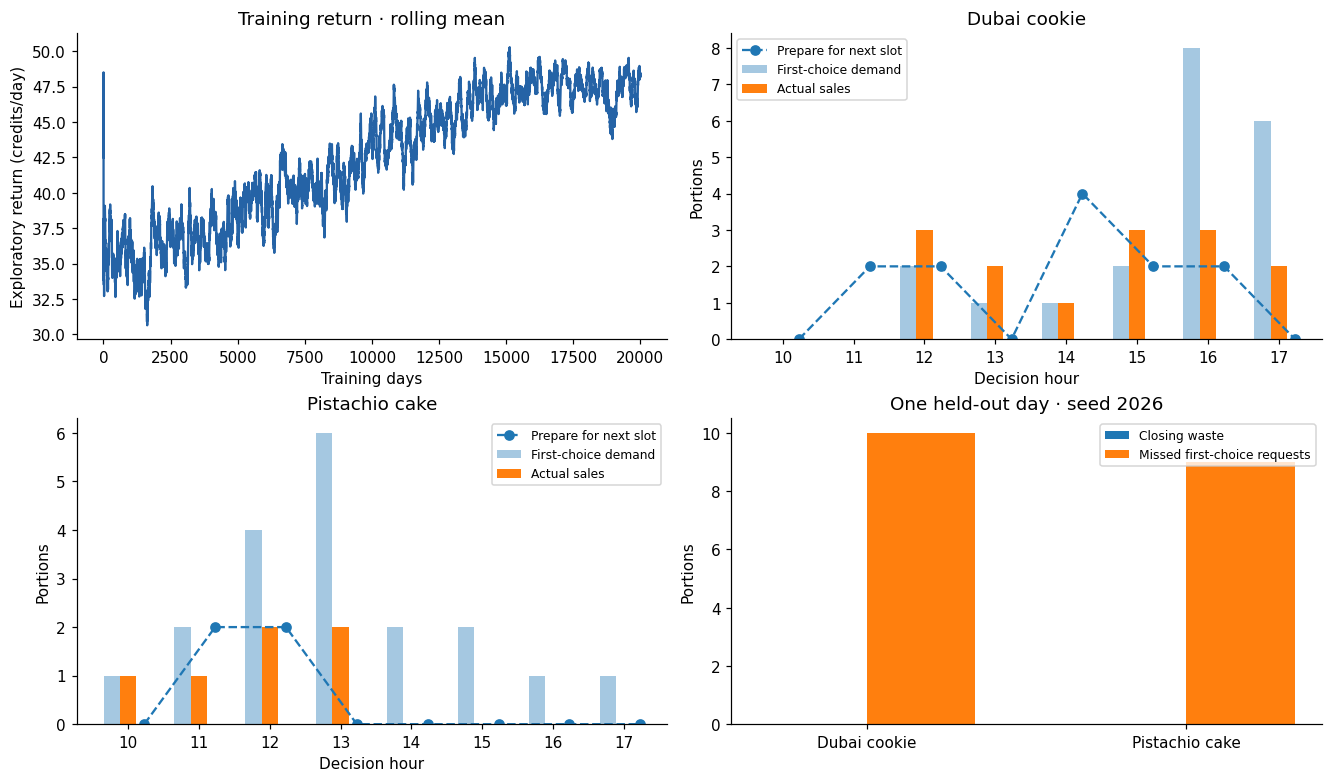

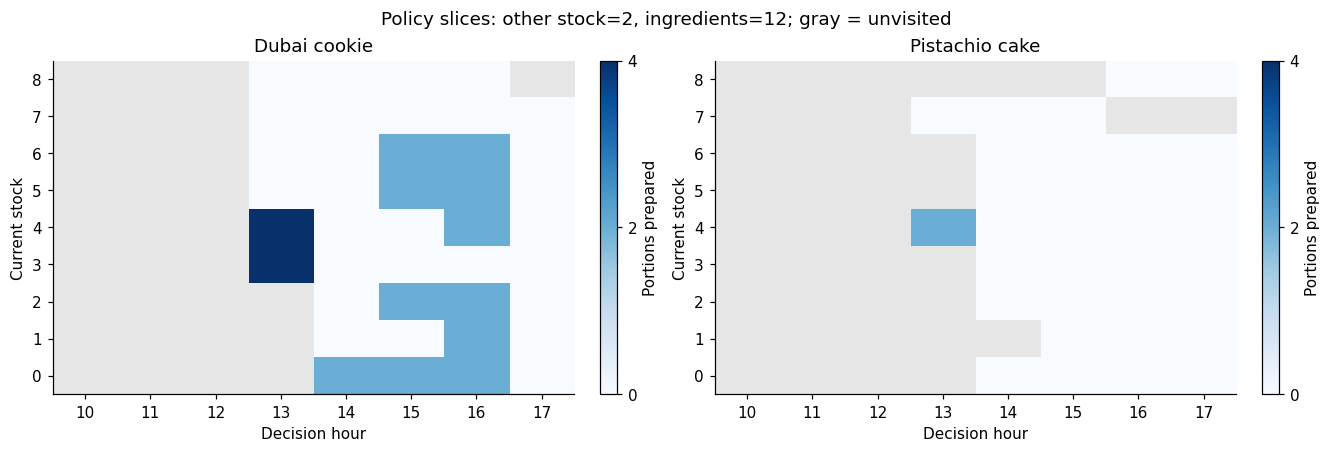

In [10]:
cafe_agent, cafe_history = train_cafe(rules, episodes=budget['cafe'], seed=0)
cafe_eval = {}
for label, policy in [('Tabular Q-learning', cafe_agent), ('Forecast-based rule', None)]:
    cafe_eval[label] = cafe_evaluate(policy, range(20000, 20000 + (20 if RUN_MODE == 'smoke' else 100)))
cafe_scoreboard = pd.DataFrame({name: frame.mean() for name, frame in cafe_eval.items()}).T
display(cafe_scoreboard.rename(columns={'return_':'return'}).round(2))
cafe_example = plot_cafe(cafe_agent, cafe_history, save_dir=OUTPUT_DIR)
plot_cafe_policy(cafe_agent, ingredients=12, other_stock=2, save_dir=OUTPUT_DIR)

**Write your explanation:** Does the learned policy anticipate each demand peak?
Compare reward, cash profit, missed customers, and waste. Why might the forecast rule win?
What does a gray policy-map cell mean?

**Optional experiment:** increase `missed_penalty` to 2.0, retrain, and compare profit and missed customers.
Do not directly compare raw rewards from two different reward definitions.

**Discussion answer:** The rule knows the simulated demand profile, so it is a strong baseline.
An undertrained table may lose. Gray means unvisited, including unreachable state combinations;
it does not mean the agent learned to wait. Higher reward can trade off profit, waste, and service.
Use the bundled 60,000-day café reference results if you want to contrast training budgets.

In [11]:
RUN_CAFE_REWARD_CHALLENGE = False
if RUN_CAFE_REWARD_CHALLENGE:
    changed_agent, _ = train_cafe(rules, episodes=budget['cafe'], seed=0,
                                 env_kwargs={'missed_penalty': 2.0})
    changed_scores = cafe_evaluate(changed_agent, range(20000,20100),
                                   env_kwargs={'missed_penalty':2.0})
    display(pd.DataFrame({'original':cafe_eval['Tabular Q-learning'].mean(),
                          'retrained_service_priority':changed_scores.mean()}).T[['profit','missed','waste']])

## 3 · Highway navigation with a DQN

![Line-art highway with only the RL-controlled ego car in blue; every other car and the background are greyscale.](../assets/figures/task_highway.png)

**Read the figure:** 1 marks the vehicle controlled by our RL policy. The grey vehicles form part of its environment.

The existing `highway-fast-v0` task has five actions: lane left, maintain, lane right, faster, slower.
The return rewards progress/speed and penalizes crashes. A high return alone does not establish safety.

Each observation has **5 vehicles × 5 features = 25 numbers**. Presence identifies real rows;
the remaining features describe position and velocity. Both methods receive the same features.
Tabular Q-learning bins them; DQN approximates values with a neural network.

**Predict:** What happens to table coverage when you make every bin finer?
Can a network return a value for an observation it has never seen exactly before?

,presence,x / 100m,y / lane width,vx / 30m/s,vy / 10m/s
0,1.0,0.000000,2.0,0.833333,0.0
1,1.0,0.205638,-1.0,-0.129236,0.0
2,1.0,0.455936,-1.0,-0.072670,0.0
3,1.0,0.717566,0.0,-0.039826,0.0
4,1.0,0.955514,-1.0,-0.129975,0.0


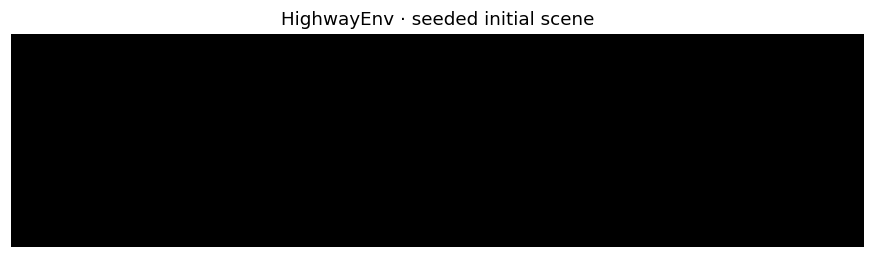

Input shape: (25,) | Actions: ['Lane left', 'Maintain', 'Lane right', 'Faster', 'Slower']


In [12]:
inspection_env = make_highway(render=True)
sample_observation, _ = inspection_env.reset(seed=0)
display(pd.DataFrame(sample_observation.reshape(5,5),
    columns=['presence','x / 100m','y / lane width','vx / 30m/s','vy / 10m/s']))
fig, ax = plt.subplots(figsize=(10,3))
ax.imshow(inspection_env.render()); ax.axis('off'); ax.set_title('HighwayEnv · seeded initial scene')
fig.savefig(OUTPUT_DIR / 'highway_scene.png', dpi=180)
plt.show()
print('Input shape:', sample_observation.shape, '| Actions:', ACTION_NAMES)
inspection_env.close()

### From a table row to network outputs
`QNetwork` maps 25 features to five action values. A batch has shape `(batch_size, 25)`;
the output has shape `(batch_size, 5)`. Actions are integer column indices.

The provided replay buffer stores transitions and samples batches. Read its five returned tensors:
states, actions, rewards, next states, and **true termination** flags.

In [13]:
class QNetwork(nn.Module):
    def __init__(self, obs_dim=25, n_actions=5):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(obs_dim, 64), nn.ReLU(),
            nn.Linear(64, 64), nn.ReLU(),
            nn.Linear(64, n_actions),
        )

    def forward(self, x):
        # (batch, 25) -> (batch, 5); no softmax: these are values, not probabilities.
        return self.net(x)


class ReplayBuffer:
    """Provided storage: keep a bounded history and sample training batches."""
    def __init__(self, capacity=20000, obs_dim=25, seed=0):
        self.states = np.zeros((capacity, obs_dim), dtype=np.float32)
        self.next_states = np.zeros_like(self.states)
        self.actions = np.zeros(capacity, dtype=np.int64)
        self.rewards = np.zeros(capacity, dtype=np.float32)
        self.terminated = np.zeros(capacity, dtype=np.float32)
        self.capacity = capacity
        self.position = 0
        self.size = 0
        self.rng = np.random.default_rng(seed)

    def add(self, state, action, reward, next_state, terminated):
        i = self.position
        self.states[i] = state
        self.actions[i] = action
        self.rewards[i] = reward
        self.next_states[i] = next_state
        self.terminated[i] = terminated  # Do not store terminated OR truncated here.
        self.position = (i + 1) % self.capacity
        self.size = min(self.size + 1, self.capacity)

    def sample(self, batch_size, device):
        indices = self.rng.integers(self.size, size=batch_size)
        arrays = (self.states, self.actions, self.rewards,
                  self.next_states, self.terminated)
        return tuple(torch.as_tensor(array[indices], device=device) for array in arrays)

In [14]:
torch.manual_seed(0)
shape_demo = QNetwork()
batch_demo = torch.zeros((4,25), dtype=torch.float32)
print('Network:', shape_demo)
print('Batch output shape:', tuple(shape_demo(batch_demo).shape))

Network: QNetwork(
  (net): Sequential(
    (0): Linear(in_features=25, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=5, bias=True)
  )
)
Batch output shape: (4, 5)


### Exercise 3 · DQN targets and loss

Complete the target and the loss. `next_values` already contains the **target network's**
maximum next-action value. Return one target per transition, then a scalar mean Huber loss.

\[
y_i=r_i+\gamma(1-\mathrm{terminated}_i)\max_{a'}Q_{\theta^-}(s'_i,a').
\]

Stop an episode after termination **or** truncation. Remove the bootstrap term only for
true termination: the highway time limit is an external cutoff.
The finite café horizon is true termination, with time included in its state.

**Hints:** `q_values.gather(1, actions.long().reshape(-1,1)).squeeze(1)` selects one output
per example. `nn.functional.smooth_l1_loss` is Huber loss. Targets must not receive gradients.

In [15]:
def dqn_targets(rewards, terminated, next_values, gamma):
    return rewards + gamma * (1.0 - terminated.float()) * next_values

def dqn_loss(q_values, actions, targets):
    chosen_q = q_values.gather(1, actions.long().reshape(-1,1)).squeeze(1)
    return nn.functional.smooth_l1_loss(chosen_q, targets.detach())

In [16]:
check_dqn(dqn_targets, dqn_loss)

Exercise 3 passed: batch shape, terminal mask, chosen actions, Huber loss and gradient direction.


### Read one training update
The online network receives gradients; the target network is periodically copied from it.
The replay buffer allows old transitions to be used again. Locate `no_grad`, `backward`,
`optimizer.step`, and `sync_target` in the provided scaffold.

In [17]:
class DQNAgent:
    def __init__(self, seed=0, gamma=.95, learning_rate=1e-3, device='cpu'):
        torch.manual_seed(seed)
        self.device = torch.device(device)
        self.online = QNetwork().to(self.device)
        self.target = copy.deepcopy(self.online).to(self.device)
        self.target.eval()
        for parameter in self.target.parameters():
            parameter.requires_grad_(False)
        self.optimizer = torch.optim.Adam(self.online.parameters(), lr=learning_rate)
        self.buffer = ReplayBuffer(seed=seed + 17)
        self.rng = np.random.default_rng(seed)
        self.gamma = gamma
        self.last_loss = np.nan

    def act(self, state, epsilon=0.):
        if self.rng.random() < epsilon:
            return int(self.rng.integers(5))
        with torch.no_grad():
            state_tensor = torch.as_tensor(state, dtype=torch.float32, device=self.device)
            values = self.online(state_tensor).cpu().numpy()
        return random_argmax(values, self.rng)

    def learn(self, batch_size=64):
        states, actions, rewards, next_states, terminated = self.buffer.sample(batch_size, self.device)
        # Fixed targets: gradients must not flow through the target network.
        with torch.no_grad():
            next_values = self.target(next_states).max(dim=1).values
            targets = dqn_targets(rewards, terminated, next_values, self.gamma)

        loss = dqn_loss(self.online(states), actions, targets)
        self.optimizer.zero_grad(set_to_none=True)
        loss.backward()
        nn.utils.clip_grad_norm_(self.online.parameters(), 10.)
        self.optimizer.step()
        self.last_loss = float(loss.detach().cpu())
        return self.last_loss

    def sync_target(self):
        self.target.load_state_dict(self.online.state_dict())

**Presenter cue:** Follow a `(64,25)` state batch through `(64,5)` outputs, action indexing,
and a scalar loss. Replay is experience reuse; the target network stabilizes a moving target.
Neither network predicts the next world state. Updating the online weights is different
from synchronizing the target network.

### Compare methods on the same interaction budget

The recorded teaching comparison trains coarse, medium, fine, and DQN agents for **2,000
interactions each, one training seed**. These are intentionally short runs and may perform poorly.
The figure reports evaluation return versus interactions and training time, plus crashes,
speed, and tabular evaluation-state coverage. Table coverage is not a metric for DQN.

To train your implementation, enable `RUN_HIGHWAY_TRAINING` in setup and rerun.
In experiment mode, the shaded region is the range over training seeds, not a confidence interval.
Evaluation uses separate seeds and does not update models or add table entries.

Comparison source: recorded teaching run: 2,000 interactions/method, seed 0


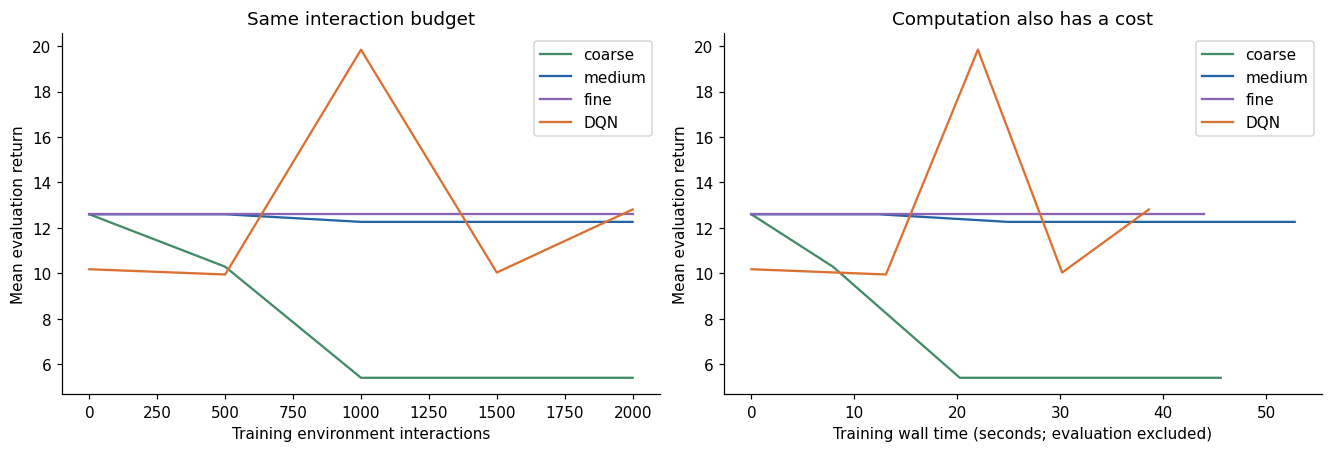

,mean_return,collision_rate,mean_speed_m_s,training_seconds,table_states,eval_state_coverage
method,,,,,,
coarse,7.877,1.0,25.125,45.595,1339.0,0.076
medium,9.521,0.9,24.606,52.780,1631.0,0.075
fine,9.813,0.8,25.050,43.984,1835.0,0.003
DQN,11.195,0.9,25.798,38.618,NaN,NaN


In [18]:
highway_agents = {}
if RUN_HIGHWAY_TRAINING:
    highway_agents, highway_curves, highway_scores = highway_comparison(
        rules, DQNAgent, steps=budget['highway'], seeds=budget['seeds'],
        eval_n=budget['eval_n'], device=DEVICE)
    highway_source = 'trained in this run'
else:
    highway_curves, highway_scores = load_cached_comparison()
    highway_source = 'recorded teaching run: 2,000 interactions/method, seed 0'
print('Comparison source:', highway_source)
highway_summary = plot_highway_comparison(highway_curves, highway_scores, save_dir=OUTPUT_DIR)

In [19]:
if highway_agents:
    print('DQN trained in THIS run:', budget['highway'], 'interactions')
    current_rollout = highway_rollout(highway_agents[('DQN', budget['seeds'][0])],
                                      seed=2026, save_path=OUTPUT_DIR / 'current_dqn.gif')
    print('Return:', current_rollout.reward.sum(), '| Crash:', current_rollout.crashed.any())
else:
    print('No new highway training requested. The next rollout is a separately labelled reference.')

No new highway training requested. The next rollout is a separately labelled reference.


### Inspect a separately trained reference policy

This supplied checkpoint used **20,000 interactions, seed 0** and the same configuration.
It is a playback example and is **not** part of the 2,000-interaction comparison above.
Its original metadata and a new local re-evaluation are stored beside the assets.
One seed or a successful animation does not establish reliable performance.

Reference training budget: 20000 | training seed: 0


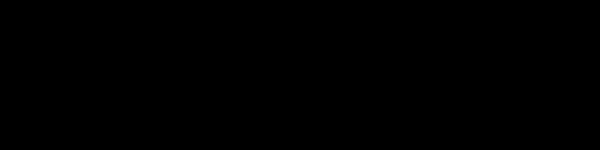

Shown episode return: 21.453554488482546 | Crash: False


In [20]:
reference_agent = PlaybackDQN()
reference_metadata = json.loads((ROOT / 'assets/checkpoints/dqn_reference_20k_seed0.json').read_text())
print('Reference training budget:', reference_metadata['steps'], '| training seed:', reference_metadata['seed'])
reference_rollout = highway_rollout(reference_agent, seed=2026,
                                    save_path=OUTPUT_DIR / 'reference_dqn.gif')
print('Shown episode return:', reference_rollout.reward.sum(), '| Crash:', reference_rollout.crashed.any())

**Explain:** Which binning gives the best coverage? Does higher coverage always mean higher return?
Why report collisions as well as reward? Why can't we include the 20,000-step checkpoint in
the short-run algorithm ranking? Write two sentences before discussing.

**Discussion answer:** Fine bins distinguish more situations but need more data to revisit them.
Coverage depends on the states the policy reaches, so it is not an isolated quality score.
Return combines several incentives and can conceal crashes. The reference policy has ten
times the teaching-run experience. Even equal interactions do not equalize computation:
DQN reuses transitions and performs different updates. Do not force the experiment to make DQN win.

## 4 · Prisoner's Dilemma: incentives and repeated responses

![Two monochrome players make highlighted C or D choices, followed by the corresponding separate payoffs in a greyscale matrix.](../assets/figures/task_prisoners_dilemma.png)

**Read the figure:** 1 shows simultaneous choices; 2 shows separate payoffs. The highlighted example has A cooperate and B defect.

Both players choose simultaneously from past information. Read each entry as **(Player A, Player B)**.
The game is general-sum: individual reward is neither a shared team score nor necessarily the
negative of the other player's reward. We use the unchanged bundled PettingZoo-Dilemmas game.

### Exercise 4 · tit-for-tat
Action `0` is cooperate; `1` is defect. Marker `2` means there was no previous partner action.
Start by cooperating; afterwards copy the partner's previous action.
Before running, predict which strategy wins against an always-cooperating partner.

In [21]:
def tit_for_tat(previous_opponent_action):
    return 0 if previous_opponent_action == 2 else int(previous_opponent_action)

Exercise 4 passed: opening cooperation and replies to both actions.


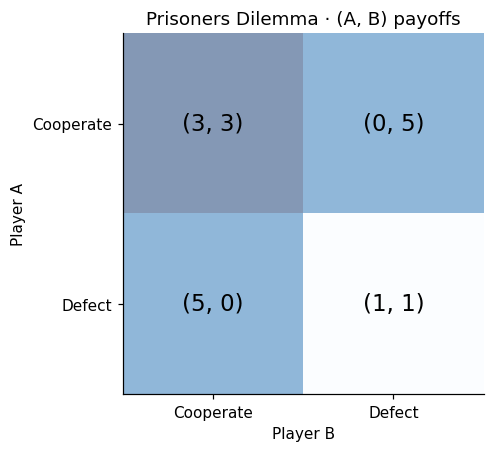

opponent,always cooperate,always defect,tit-for-tat
strategy,,,
always cooperate,3.0,0.00,3.0
always defect,5.0,1.00,1.2
tit-for-tat,3.0,0.95,3.0


In [22]:
check_tit_for_tat(tit_for_tat)
pd_matrix = plot_payoffs('prisoners_dilemma')
strategies = {'always cooperate':'always_cooperate',
              'always defect':'always_defect', 'tit-for-tat':tit_for_tat}
tournament = []
for name, strategy in strategies.items():
    for opponent_name, opponent in strategies.items():
        match = social_match('prisoners_dilemma',strategy,opponent,nrounds=20)
        tournament.append(dict(strategy=name,opponent=opponent_name,
                               mean_reward_A=match.reward_a.mean(),
                               mutual_cooperation=match.both_cooperate.mean()))
tournament = pd.DataFrame(tournament)
display(tournament.pivot(index='strategy',columns='opponent',values='mean_reward_A'))
if SHOW_WIDGETS:
    dilemma_ui = dilemma_controls(tit_for_tat)

**Explain:** Does tit-for-tat earn the most against every opponent? How does a present action
affect a reactive partner's later response? What is different from a one-shot game?
The tournament is a strategy comparison; it is not itself RL training.

**Discussion answer:** Always defect exploits always cooperate, earning 5 instead of 3.
Against tit-for-tat, an initial defection changes future replies, so immediate payoff is
not the whole decision. Tit-for-tat is a hand-coded strategy, not a universally optimal
learning algorithm. Finite repeated play does not guarantee learned cooperation.

In [23]:
if RUN_SOCIAL_TRAINING:
    pd_agent_a, pd_agent_b, pd_history = train_social('prisoners_dilemma',rules,
        episodes=budget['social'],opponent='learner',seed=0)
    pd_match = social_match('prisoners_dilemma',pd_agent_a,pd_agent_b)
    plot_social(pd_history,pd_match,'prisoners_dilemma')
else:
    print('Optional extension: enable RUN_SOCIAL_TRAINING to train two independent Q-learners.')

Optional extension: enable RUN_SOCIAL_TRAINING to train two independent Q-learners.


## 5 · Simple Spread: one team, one reward

![Monochrome robots and landmarks with blue coverage paths: 1 duplicate nearest-target choices, 2 different assignments, 3 one identical team reward.](../assets/figures/task_simple_spread.png)

**Read the figure:** 1 shows duplicated coverage; 2 shows complementary assignments; 3 shows the same reward for everyone. A, B and C correspond to agent_0, agent_1 and agent_2.

Three movable agents must cover three fixed landmarks. If everyone follows their own
nearest landmark, they can duplicate each other's work and leave other landmarks unattended.
There are no preassigned jobs. Agents need complementary behavior to cover the whole scene.

| Element | Meaning |
|---|---|
| Observe | Own velocity and position, relative landmark and teammate positions; 18 values per agent |
| Act | `0` stay, `1` left, `2` right, `3` down, `4` up; all agents choose before the world advances |
| Receive | Every agent receives **the same team coverage reward** at every step |
| Configuration | Actual MPE2 Simple Spread, `N=3`, `local_ratio=0.0`, discrete actions, 60-step horizon |

The four communication entries in each observation are zero: these agents are silent.
Physical collisions remain, but there is **no individual collision penalty**, private
distance reward, or individual bonus. Zero is the best possible coverage reward;
feedback improves as distances shrink, even before all landmarks are covered.

### Exercise 5 · calculate a shared team reward with NumPy

For each **landmark**, find its nearest agent. Sum those distances and negate:

\[
R_{\mathrm{team}}=-\sum_{j=1}^{N}\min_i\|x_i-\ell_j\|_2,
\qquad r_0=r_1=r_2=R_{\mathrm{team}}.
\]

Return one scalar. Inputs have shape `(n_agents, 2)` and `(n_landmarks, 2)`.
The distance matrix should have shape `(n_agents, n_landmarks)`.
**Hint:** broadcast with `[:, None, :]` and `[None, :, :]`; take a norm over coordinates,
then a minimum **over agents**, not over landmarks.

Before coding: with landmarks at `(0,0)` and `(10,0)`, what happens when agents at
`(1,0)` and `(2,0)` both move left? How would sending one agent right change team coverage?

In [24]:
def team_reward(agent_positions, landmark_positions):
    distances = np.linalg.norm(
        agent_positions[:, None, :] - landmark_positions[None, :, :], axis=-1)
    return float(-distances.min(axis=0).sum())

In [25]:
check_team_reward(team_reward)

# One real parallel environment step: all decisions are submitted together.
spread_env = make_spread()
try:
    observations, _ = reset_spread(spread_env, seed=2026)
    print('Observation shapes:', {name: obs.shape for name, obs in observations.items()})
    actions = {name: 0 for name in spread_env.agents}  # everyone stays for this inspection
    next_observations, rewards, terminated, truncated, infos = spread_env.step(actions)
    agent_positions, landmark_positions = spread_positions(spread_env)
    calculated = team_reward(agent_positions, landmark_positions)
    np.testing.assert_allclose(list(rewards.values()), calculated)
    print('Actual environment rewards:', dict(rewards))
    print('Your calculated team reward:', calculated)
finally:
    spread_env.close()

Exercise 5 passed: shared scalar, coverage direction, Euclidean distances and invariance.
Observation shapes: {'agent_0': (18,), 'agent_1': (18,), 'agent_2': (18,)}
Actual environment rewards: {'agent_0': -2.7796577623925978, 'agent_1': -2.7796577623925978, 'agent_2': -2.7796577623925978}
Your calculated team reward: -2.7796577623925978


### Compare two transparent controllers

**Predict first:** which controller will cover more landmarks from this clustered start?

1. **Nearest:** each agent independently steers toward its nearest landmark, reconsidering each step.
2. **Assignment:** a centralized planner uses all positions to assign a different landmark to each agent,
   minimizing the sum of starting travel distances. Agents then steer toward those assigned targets.

Both are **hand-coded baselines, not trained RL agents**. Both use global position information.
The assignment planner is a reference for coordination, not a claim about decentralized learning.
Both controllers use the same starting layout, simulator, actions, physics and shared reward.
Discrete steering and collisions mean assignment does not guarantee perfect coverage.

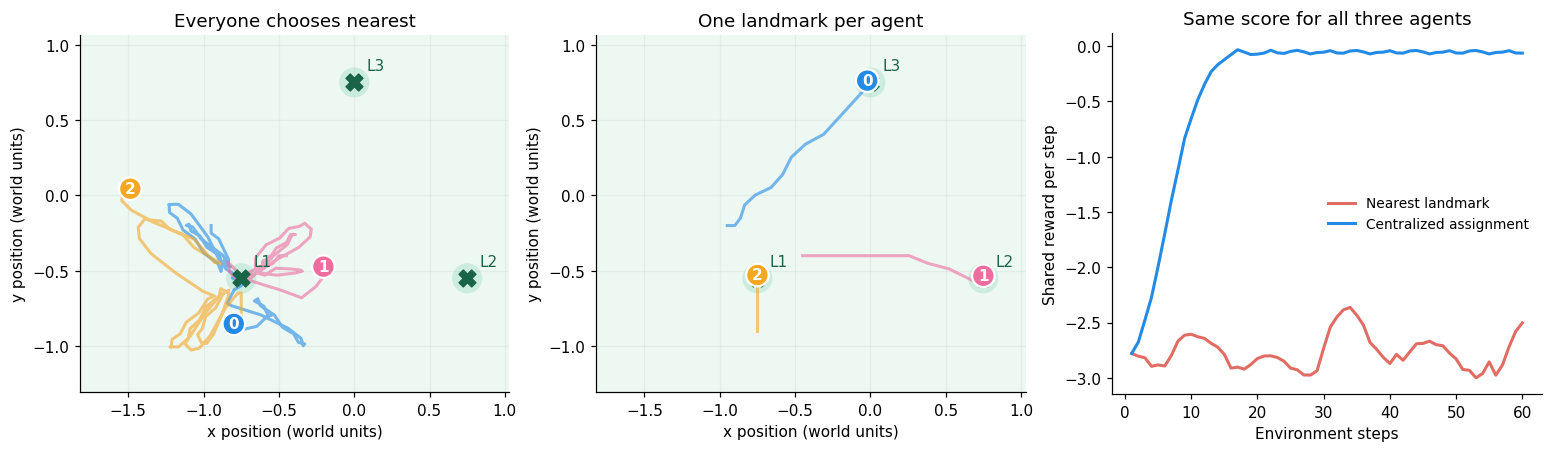

,controller,team_return,final_team_reward,reward_identical_for_all_agents
0,Nearest landmark,-166.003,-2.504,True
1,Centralized assignment,-21.702,-0.063,True


Team return is the sum over time of ONE shared reward; do not multiply by three.


In [26]:
nearest_rollout = spread_rollout('nearest', seed=2026)
assigned_rollout = spread_rollout('assignment', seed=2026)
plot_spread_comparison(nearest_rollout, assigned_rollout,
                       save_path=OUTPUT_DIR / 'simple_spread_comparison.png')
spread_scoreboard = pd.DataFrame([
    dict(controller=label, team_return=rollout['history'].team_reward.sum(),
         final_team_reward=rollout['history'].team_reward.iloc[-1],
         reward_identical_for_all_agents=True)
    for label, rollout in [('Nearest landmark', nearest_rollout),
                            ('Centralized assignment', assigned_rollout)]
])
display(spread_scoreboard.round(3))
print('Team return is the sum over time of ONE shared reward; do not multiply by three.')
if SHOW_WIDGETS:
    spread_ui = spread_controls(team_reward, nearest_rollout, assigned_rollout)

**Ordinary-code alternative:** the comparison above works without widgets.
Change `seed` and `layout='random'` in **both** rollout calls to inspect another matched start.
The interactive Play button or step slider shows one actual simulator trajectory at a time.

**Explain:** Why can moving away from your own nearest landmark help the team?
If agent 0 stays still while agent 1 improves coverage, why do both receive a better reward?
Does an identical reward mean their observations, actions, or network weights must be identical?
What evidence would you need before claiming that learned agents can coordinate?

**Discussion answer:** The reward sums nearest-agent distances **per landmark**.
Putting extra agents beside an already covered landmark adds little coverage benefit.
In the two-landmark example, the starting reward is −9, crowding the left gives −10,
and placing one agent on each landmark gives 0. All agents receive the same score,
including an agent that stays still. Reward sharing does not identify who caused the improvement:
this is the credit-assignment challenge. Observations and actions can differ, and sharing
network weights is a separate design choice. The displayed controllers are not learned policies.
Training and held-out evaluation over multiple seeds would be needed to assess learned coordination.

**Optional extension:** repeat both controllers on five matched random layouts and compare
team returns. A single favorable starting scene cannot establish general superiority.
For a future multi-agent RL extension, each agent's update would use its own transition
and this same scalar team reward; the environment itself does not assign landmark roles.

The optional **Prisoner's Dilemma** learners observe remaining rounds and the previous
joint action from their own perspective. Both choose before the new joint action is submitted.
When both learn, each faces a changing opponent; convergence and cooperation are not guaranteed.
That adapter scores exactly the requested number of rounds and ignores the upstream
version's additional empty completion call. Simple Spread uses MPE2's parallel API instead.

## 6 · Keep the evidence and reflect

Results go to a new directory under `results/`, which Git ignores. The run manifest labels
fresh training versus cached comparisons. Figures and GIFs can be reused in your notes.
No Google account, Drive mount, external dataset, or GPU is required for the local lab.

In [27]:
np.savez_compressed(OUTPUT_DIR / 'cafe_q_table.npz',q=cafe_agent.q,visits=cafe_agent.visits)
cafe_history.to_csv(OUTPUT_DIR / 'cafe_history.csv',index=False)
cafe_scoreboard.to_csv(OUTPUT_DIR / 'cafe_scoreboard.csv')
highway_curves.to_csv(OUTPUT_DIR / 'highway_learning_curves.csv',index=False)
highway_scores.to_csv(OUTPUT_DIR / 'highway_heldout_evaluation.csv',index=False)
tournament.to_csv(OUTPUT_DIR / 'prisoners_dilemma_tournament.csv',index=False)
spread_scoreboard.to_csv(OUTPUT_DIR / 'simple_spread_scoreboard.csv',index=False)
nearest_rollout['history'].to_csv(OUTPUT_DIR / 'simple_spread_nearest.csv',index=False)
assigned_rollout['history'].to_csv(OUTPUT_DIR / 'simple_spread_assignment.csv',index=False)
if highway_agents:
    current_dqn = highway_agents[('DQN',budget['seeds'][0])]
    np.savez_compressed(OUTPUT_DIR / 'current_dqn_weights.npz',
        **{k:v.detach().cpu().numpy() for k,v in current_dqn.online.state_dict().items()})
manifest = {'run_mode':RUN_MODE,'versions':VERSIONS,'budget':budget,
            'cafe_source':'trained in this run','highway_comparison_source':highway_source,
            'highway_config':HIGHWAY_CONFIG,'reference_rollout':'supplied 20,000-step checkpoint, seed 0',
            "prisoners_dilemma_training":RUN_SOCIAL_TRAINING,
            'simple_spread':{'package':'mpe2','version':VERSIONS['mpe2'],'local_ratio':0.0,
                             'agents':3,'steps':60,'seed':2026,'layout':'clustered',
                             'controllers':'hand-coded nearest and centralized assignment',
                             'training':False}}
(OUTPUT_DIR / 'run_metadata.json').write_text(json.dumps(manifest,indent=2))
print('Saved results:',OUTPUT_DIR)

Saved results: /Users/sarahxu/Desktop/Coding-session-for-Neuroscience-inspired-AI/results/teaching_20261031_171901


**Exit questions:**
1. What makes a state useful for predicting future reward?
2. What changes between a Q-table and a Q-network? What stays the same?
3. Why is an evaluation episode different from a training episode?
4. What changes when another agent also makes decisions?

**References:** [Gymnasium environment API](https://gymnasium.farama.org/api/env/),
[time limits](https://gymnasium.farama.org/tutorials/gymnasium_basics/handling_time_limits/),
[HighwayEnv](https://highway-env.farama.org/),
[PyTorch DQN tutorial](https://docs.pytorch.org/tutorials/intermediate/reinforcement_q_learning.html),
[PettingZoo-Dilemmas source](https://github.com/mrochk/pettingzoo-dilemmas),
[Simple Spread reward definition](https://mpe2.farama.org/environments/simple_spread/).
This lab pins MPE2 0.0.1 for compatibility with the existing pygame-based Mac environment.

Lecture connections from the supplied notebook: `3.1_RLmodels-part1`, pp. 30–35 and 46–53;
`3.2_DeepRL-part1`, pp. 15–27; `3.2_DeepRL-part2`, pp. 32–39.
The lecture PDFs are not redistributed here. See `vendor/PROVENANCE.json` for the pinned game commit.